# Tugas 2: Pipeline Pemrosesan Batch dengan Hadoop MapReduce dan Spark

**Mata kuliah:** IT Platform and Infrastructure
**Kelompok 21**

| No | Nama | NIM |
|---|---|---|
| 1 | Eka Putra Kurnia | 25.55.2927 |
| 2 | Zahrul Amri Hutabarat | 25.55.2900 |
| 3 | Bujur Depoin Sianipar | 25.55.2879 |
| 4 | Riyan Pratomo Saputra | 25.55.2857 |

**Studi kasus:** Log Web Server — *NASA HTTP Access Logs* (Juli + Agustus 1995, ±356 MB, ±3,46 juta request).

**Tiga analisis batch** yang masing-masing dikerjakan dengan tiga pendekatan
(MapReduce/mrjob, Spark RDD, Spark DataFrame):

| Kode | Analisis | Key → value |
|---|---|---|
| `host` | Jumlah request per host (IP/nama host) | `host → 1`, dijumlah |
| `status` | Distribusi HTTP status code | `status → 1`, dijumlah |
| `hour` | Total traffic (bytes) per jam-dalam-sehari (00–23) | `jam → bytes`, dijumlah |

**Isi notebook:**
0. Pengaturan · 1. Setup lingkungan · 2. Persiapan dataset · 3. Parser bersama ·
4. MapReduce (mrjob) · 5. Spark RDD · 6. Spark DataFrame · 7. Validasi output ·
8. Alat ukur · 9. Benchmark · 10. Hasil benchmark · 11. Hasil analisis data · 12. Catatan untuk laporan

## 0. Pengaturan

- `QUICK_MODE = True` hanya memakai `QUICK_LINES` baris pertama dataset. Gunakan untuk mengecek
  bahwa seluruh notebook berjalan tanpa error sebelum menjalankan benchmark penuh.
- `REPEATS` = berapa kali setiap pengukuran diulang (hasilnya dirata-rata).

Kedua nilai juga bisa diatur lewat *environment variable* dengan nama yang sama.

In [1]:
import os

QUICK_MODE = os.environ.get("QUICK_MODE", "0") == "1"
QUICK_LINES = 200_000
REPEATS = int(os.environ.get("REPEATS", "3"))

DATA_DIR = "data"
RESULT_DIR = "hasil"
ANALYSES = ["host", "status", "hour"]

os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)
print(f"QUICK_MODE={QUICK_MODE}, REPEATS={REPEATS}")

QUICK_MODE=False, REPEATS=3


## 1. Setup Lingkungan Kerja

Mengikuti Tahap 1 spesifikasi, dengan tiga penyesuaian:

1. **Java 17, bukan Java 8.** `pip install pyspark` memasang PySpark 4.x, yang membutuhkan Java 17
   atau lebih baru. Dengan Java 8, Spark gagal dijalankan.
2. **`setuptools`** ikut dipasang karena mrjob 0.7.4 (rilis terakhir, 2020) masih memakai modul
   `distutils` yang sudah dihapus dari pustaka standar Python 3.12; `setuptools` menyediakan penggantinya.
3. **`standard-pipes`** dipasang bila Python ≥ 3.13, karena mrjob juga memakai modul `pipes`
   yang dihapus di Python 3.13.

Instalasi hanya dijalankan di Google Colab; di luar Colab sel ini memakai paket yang sudah terpasang.

In [2]:
import importlib
import sys

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    !apt-get install -y openjdk-17-jdk-headless -qq > /dev/null
    !pip install -q pyspark mrjob psutil setuptools
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
    if sys.version_info >= (3, 13):
        !pip install -q standard-pipes
    importlib.invalidate_caches()
else:
    print("Bukan di Google Colab: instalasi dilewati.")

Spesifikasi perangkat lunak dan mesin (dicatat untuk Bab 1 laporan):

In [3]:
import platform
import shutil
import subprocess

import mrjob
import psutil
import pyspark

java_bin = os.path.join(os.environ["JAVA_HOME"], "bin", "java") if "JAVA_HOME" in os.environ else shutil.which("java")
java_version = subprocess.run([java_bin, "-version"], capture_output=True, text=True).stderr.splitlines()[0]

ENV_INFO = {
    "Sistem operasi": platform.platform(),
    "Python": platform.python_version(),
    "PySpark": pyspark.__version__,
    "mrjob": mrjob.__version__,
    "Java": java_version,
    "Inti CPU (logical)": psutil.cpu_count(logical=True),
    "RAM total (GB)": round(psutil.virtual_memory().total / 1024**3, 1),
}
for key, value in ENV_INFO.items():
    print(f"{key:<20}: {value}")

Sistem operasi      : Linux-6.6.122+-x86_64-with-glibc2.39
Python              : 3.13.16
PySpark             : 4.0.4
mrjob               : 0.7.4
Java                : openjdk version "17.0.20.1" 2026-08-18
Inti CPU (logical)  : 2
RAM total (GB)      : 12.7


## 2. Persiapan Dataset

Log diunduh dari *Internet Traffic Archive* (LBL), lalu kedua bulan digabung menjadi satu berkas teks.

**Normalisasi:** sebagian kecil baris memuat byte non-ASCII atau karakter kontrol (misalnya tab di
dalam URL). Regex Python (dipakai mrjob & RDD) dan regex Java (dipakai DataFrame) memperlakukan
karakter seperti itu sedikit berbeda, sehingga setiap byte di luar ASCII yang dapat dicetak diganti
dengan `?`. Dengan begitu ketiga pendekatan membaca teks yang persis sama.

In [4]:
import gzip
import urllib.request
from pathlib import Path

LOG_URLS = [
    "https://ita.ee.lbl.gov/traces/NASA_access_log_Jul95.gz",
    "https://ita.ee.lbl.gov/traces/NASA_access_log_Aug95.gz",
]
FULL_PATH = Path(DATA_DIR) / "nasa_access_log.txt"
QUICK_PATH = Path(DATA_DIR) / "nasa_access_log_quick.txt"

# Tabel penerjemah: byte ASCII yang dapat dicetak (spasi s.d. ~) dipertahankan, sisanya jadi "?".
PRINTABLE_ONLY = bytes(b if 32 <= b <= 126 else ord("?") for b in range(256))

gz_paths = []
for url in LOG_URLS:
    gz_path = Path(DATA_DIR) / url.rsplit("/", 1)[-1]
    if not gz_path.exists():
        print(f"Mengunduh {url} ...")
        urllib.request.urlretrieve(url, gz_path)
    gz_paths.append(gz_path)

if not FULL_PATH.exists():
    with open(FULL_PATH, "wb") as out:
        for gz_path in gz_paths:
            with gzip.open(gz_path, "rb") as f:
                for raw in f:
                    out.write(raw.rstrip(b"\r\n").translate(PRINTABLE_ONLY) + b"\n")

if QUICK_MODE and not QUICK_PATH.exists():
    with open(FULL_PATH, "rb") as src, open(QUICK_PATH, "wb") as out:
        for i, raw in enumerate(src):
            if i >= QUICK_LINES:
                break
            out.write(raw)

DATA_PATH = str(QUICK_PATH if QUICK_MODE else FULL_PATH)

In [5]:
with open(DATA_PATH, "rb") as f:
    total_lines = sum(1 for _ in f)

print(f"Berkas     : {DATA_PATH}")
print(f"Ukuran     : {os.path.getsize(DATA_PATH) / 1024**2:,.1f} MB")
print(f"Jumlah baris: {total_lines:,}")
print("\nContoh 3 baris pertama:")
with open(DATA_PATH) as f:
    for _ in range(3):
        print(" ", f.readline().rstrip())

Berkas     : data/nasa_access_log.txt
Ukuran     : 355.8 MB
Jumlah baris: 3,461,613

Contoh 3 baris pertama:
  199.72.81.55 - - [01/Jul/1995:00:00:01 -0400] "GET /history/apollo/ HTTP/1.0" 200 6245
  unicomp6.unicomp.net - - [01/Jul/1995:00:00:06 -0400] "GET /shuttle/countdown/ HTTP/1.0" 200 3985
  199.120.110.21 - - [01/Jul/1995:00:00:09 -0400] "GET /shuttle/missions/sts-73/mission-sts-73.html HTTP/1.0" 200 4085


## 3. Parser Bersama

Satu pola regex untuk mengambil **host, jam, status, dan bytes** dari setiap baris, disimpan di
`nasa_parser.py` agar dipakai oleh mrjob dan Spark RDD. Spark DataFrame memakai **pola yang sama**
lewat `regexp_extract`. Baris yang tidak cocok dengan pola dibuang dengan cara yang sama di ketiganya.

Format baris (*Common Log Format*):

```
199.72.81.55 - - [01/Jul/1995:00:00:01 -0400] "GET /history/apollo/ HTTP/1.0" 200 6245
   host                 waktu (jam = 00)              request               status bytes
```

Catatan: kolom pertama tidak selalu IP; sering berupa nama host (misalnya `unicomp6.unicomp.net`).

In [6]:
%%writefile nasa_parser.py
"""Parser log NASA (Common Log Format) yang dipakai bersama oleh mrjob dan Spark RDD."""
import re

# Grup: 1 = host, 2 = jam (00-23), 3 = status HTTP, 4 = bytes ("-" bila tidak ada).
# Bagian request memakai ".*" (greedy) karena sebagian URL memuat tanda kutip.
# Hanya memakai sintaks yang artinya sama di regex Python dan Java (dipakai Spark DataFrame).
LOG_PATTERN = (
    r'^(\S+) \S+ \S+ \[\d{2}/\w{3}/\d{4}:(\d{2}):\d{2}:\d{2} [^\]]*\] ".*" (\d{3}) (\d+|-)$'
)
_LOG_RE = re.compile(LOG_PATTERN)


def parse_line(line):
    """Kembalikan (host, jam, status, bytes), atau None bila baris tidak sesuai format."""
    match = _LOG_RE.match(line)
    if match is None:
        return None
    host, hour, status, nbytes = match.groups()
    return host, int(hour), int(status), 0 if nbytes == "-" else int(nbytes)

Overwriting nasa_parser.py


In [7]:
import importlib

import nasa_parser
importlib.reload(nasa_parser)
from nasa_parser import LOG_PATTERN, parse_line

examples = [
    '199.72.81.55 - - [01/Jul/1995:00:00:01 -0400] "GET /history/apollo/ HTTP/1.0" 200 6245',
    'frank.mtsu.edu - - [03/Jul/1995:02:41:15 -0400] "GET /images/" HTTP/1.0" 404 -',
    'alyssa.p',
]
for line in examples:
    print(f"{parse_line(line)!s:<45} <- {line[:70]}")

# Hitung baris valid/tidak valid sebagai acuan validasi di bagian 7.
with open(DATA_PATH) as f:
    invalid_lines = [line.rstrip("\n") for line in f if parse_line(line.rstrip("\n")) is None]
valid_lines = total_lines - len(invalid_lines)
print(f"\nBaris valid      : {valid_lines:,}")
print(f"Baris tidak valid: {len(invalid_lines):,} -> {invalid_lines[:5]}")

('199.72.81.55', 0, 200, 6245)                <- 199.72.81.55 - - [01/Jul/1995:00:00:01 -0400] "GET /history/apollo/ HT
('frank.mtsu.edu', 2, 404, 0)                 <- frank.mtsu.edu - - [03/Jul/1995:02:41:15 -0400] "GET /images/" HTTP/1.
None                                          <- alyssa.p

Baris valid      : 3,461,612
Baris tidak valid: 1 -> ['alyssa.p']


## 4. Implementasi MapReduce (mrjob)

Satu skrip `mr_nasa.py` menangani ketiga analisis lewat argumen `--analysis`:

- **Mapper**: mem-parsing baris, lalu mengeluarkan pasangan key-value sesuai analisis.
- **Reducer**: menjumlahkan semua value untuk key yang sama.
- **Combiner** (opsional, `--use-combiner`): menjumlahkan sebagian di sisi Map *sebelum* shuffle.
  Contoh kode di spesifikasi tidak memakai combiner; di sini dijalankan versi **tanpa** (sesuai
  spesifikasi) dan **dengan** combiner, karena `reduceByKey` di Spark melakukannya otomatis.

Job dijalankan dengan runner **`local`**: mapper dan reducer berjalan sebagai beberapa subproses
paralel dengan tahap sort/shuffle di antaranya, meniru alur Hadoop di satu mesin. Ini **bukan**
cluster Hadoop sungguhan (tidak ada HDFS/YARN).

In [8]:
%%writefile mr_nasa.py
"""Job MapReduce (mrjob) untuk tiga analisis log web server NASA."""
from mrjob.job import MRJob
from mrjob.step import MRStep

from nasa_parser import parse_line


class MRNasaLog(MRJob):
    # nasa_parser.py ikut disalin ke direktori kerja setiap task.
    FILES = ["nasa_parser.py"]

    def configure_args(self):
        super().configure_args()
        self.add_passthru_arg("--analysis", choices=["host", "status", "hour"], default="host")
        self.add_passthru_arg("--use-combiner", action="store_true")

    def mapper(self, _, line):
        record = parse_line(line)
        if record is None:
            return
        host, hour, status, nbytes = record
        if self.options.analysis == "host":
            yield host, 1
        elif self.options.analysis == "status":
            yield status, 1
        else:
            yield hour, nbytes

    def combiner(self, key, values):
        yield key, sum(values)

    def reducer(self, key, values):
        yield key, sum(values)

    def steps(self):
        return [
            MRStep(
                mapper=self.mapper,
                combiner=self.combiner if self.options.use_combiner else None,
                reducer=self.reducer,
            )
        ]


if __name__ == "__main__":
    MRNasaLog.run()

Overwriting mr_nasa.py


In [9]:
import logging

import mr_nasa
importlib.reload(mr_nasa)
from mr_nasa import MRNasaLog

# Sembunyikan peringatan "No configs specified for local runner" (memang tidak memakai mrjob.conf).
logging.getLogger("mrjob").setLevel(logging.ERROR)


def run_mrjob(analysis, path, combiner=False):
    # Jalankan satu job mrjob dan kembalikan hasilnya sebagai dict {key: total}.
    args = ["-r", "local", "--analysis", analysis, path]
    if combiner:
        args.append("--use-combiner")
    job = MRNasaLog(args=args)
    with job.make_runner() as runner:
        runner.run()
        return dict(job.parse_output(runner.cat_output()))

## 5. Implementasi Apache Spark — RDD API

SparkSession dibuat sekali dengan `master("local[*]")` (semua inti CPU di mesin ini).
Waktu menyalakan Spark (JVM + SparkSession) dicatat terpisah karena hanya terjadi sekali,
tetapi bisa dominan pada data kecil.

Pada RDD, `parse_line` adalah fungsi Python, sehingga Spark harus menjalankan *Python worker*
dan memindahkan data bolak-balik antara JVM dan Python.

In [10]:
import time
from operator import add

from pyspark.sql import SparkSession

start = time.perf_counter()
spark = (
    SparkSession.builder
    .appName("BatchProcessingBenchmarking")
    .master("local[*]")
    .config("spark.driver.memory", "4g")
    .config("spark.ui.showConsoleProgress", "false")
    .getOrCreate()
)
SPARK_STARTUP_S = time.perf_counter() - start

sc = spark.sparkContext
sc.setLogLevel("ERROR")
sc.addPyFile("nasa_parser.py")
print(f"SparkSession siap dalam {SPARK_STARTUP_S:.2f} detik (Spark {spark.version}, {sc.defaultParallelism} inti)")

SparkSession siap dalam 26.13 detik (Spark 4.0.4, 2 inti)


In [11]:
def rdd_parsed(path):
    # Transformation saja (lazy): belum ada data yang dibaca.
    return sc.textFile(path).map(parse_line).filter(lambda rec: rec is not None)


def rdd_host(parsed):
    return dict(parsed.map(lambda rec: (rec[0], 1)).reduceByKey(add).collect())


def rdd_status(parsed):
    return dict(parsed.map(lambda rec: (rec[2], 1)).reduceByKey(add).collect())


def rdd_hour(parsed):
    return dict(parsed.map(lambda rec: (rec[1], rec[3])).reduceByKey(add).collect())


RDD_ANALYSES = {"host": rdd_host, "status": rdd_status, "hour": rdd_hour}


def run_rdd(analysis, path):
    # collect() adalah action: di sinilah Spark benar-benar menjalankan DAG.
    return RDD_ANALYSES[analysis](rdd_parsed(path))

## 6. Implementasi Apache Spark — DataFrame API

Pola regex yang sama dijalankan di JVM lewat `rlike` dan `regexp_extract`, tanpa Python worker,
sehingga dapat dioptimalkan oleh Catalyst/Tungsten. Baris disaring dengan `rlike` lebih dulu agar
`cast` hanya dikenakan pada baris yang valid.

In [12]:
from pyspark.sql import functions as F


def df_parsed(path):
    value = F.col("value")

    def field(group):
        return F.regexp_extract(value, LOG_PATTERN, group)

    return (
        spark.read.text(path)
        .filter(value.rlike(LOG_PATTERN))
        .select(
            field(1).alias("host"),
            field(2).cast("int").alias("hour"),
            field(3).cast("int").alias("status"),
            F.when(field(4) == "-", 0).otherwise(field(4).cast("long")).alias("bytes"),
        )
    )


def df_host(parsed):
    rows = parsed.groupBy("host").agg(F.count("*").alias("total_request")).collect()
    return {row["host"]: row["total_request"] for row in rows}


def df_status(parsed):
    rows = parsed.groupBy("status").agg(F.count("*").alias("total_request")).collect()
    return {row["status"]: row["total_request"] for row in rows}


def df_hour(parsed):
    rows = parsed.groupBy("hour").agg(F.sum("bytes").alias("total_bytes")).collect()
    return {row["hour"]: row["total_bytes"] for row in rows}


DF_ANALYSES = {"host": df_host, "status": df_status, "hour": df_hour}


def run_df(analysis, path):
    return DF_ANALYSES[analysis](df_parsed(path))

In [13]:
# Rencana eksekusi (DAG) yang disusun Spark untuk analisis per host.
df_parsed(DATA_PATH).groupBy("host").count().explain()

== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- HashAggregate(keys=[host#2], functions=[count(1)])
   +- Exchange hashpartitioning(host#2, 200), ENSURE_REQUIREMENTS, [plan_id=15]
      +- HashAggregate(keys=[host#2], functions=[partial_count(1)])
         +- Project [regexp_extract(value#0, ^(\S+) \S+ \S+ \[\d{2}/\w{3}/\d{4}:(\d{2}):\d{2}:\d{2} [^\]]*\] ".*" (\d{3}) (\d+|-)$, 1) AS host#2]
            +- Filter (isnotnull(value#0) AND RLIKE(value#0, ^(\S+) \S+ \S+ \[\d{2}/\w{3}/\d{4}:(\d{2}):\d{2}:\d{2} [^\]]*\] ".*" (\d{3}) (\d+|-)$))
               +- FileScan text [value#0] Batched: false, DataFilters: [isnotnull(value#0), RLIKE(value#0, ^(\S+) \S+ \S+ \[\d{2}/\w{3}/\d{4}:(\d{2}):\d{2}:\d{2} [^\]]*..., Format: Text, Location: InMemoryFileIndex(1 paths)[file:/content/data/nasa_access_log.txt], PartitionFilters: [], PushedFilters: [IsNotNull(value)], ReadSchema: struct<value:string>




## 7. Validasi: Output Ketiga Pendekatan Identik

Setiap pendekatan dijalankan sekali pada data yang sama, lalu hasilnya dibandingkan key demi key.
Putaran ini sekaligus berfungsi sebagai **pemanasan** (*warm-up*): berkas data masuk ke cache
sistem operasi dan JVM sudah "panas", sehingga putaran benchmark berikutnya lebih adil.
Hasil putaran ini tidak dimasukkan ke benchmark.

In [14]:
APPROACHES = {
    "MapReduce": lambda analysis: run_mrjob(analysis, DATA_PATH),
    "MapReduce + combiner": lambda analysis: run_mrjob(analysis, DATA_PATH, combiner=True),
    "Spark RDD": lambda analysis: run_rdd(analysis, DATA_PATH),
    "Spark DataFrame": lambda analysis: run_df(analysis, DATA_PATH),
}

outputs = {}
for analysis in ANALYSES:
    for name, run in APPROACHES.items():
        start = time.perf_counter()
        outputs[(name, analysis)] = run(analysis)
        print(f"{analysis:<7} {name:<22} selesai dalam {time.perf_counter() - start:6.1f} s")

host    MapReduce              selesai dalam   67.6 s
host    MapReduce + combiner   selesai dalam   64.7 s
host    Spark RDD              selesai dalam   27.8 s
host    Spark DataFrame        selesai dalam   33.5 s
status  MapReduce              selesai dalam   65.1 s
status  MapReduce + combiner   selesai dalam   63.4 s
status  Spark RDD              selesai dalam   20.1 s
status  Spark DataFrame        selesai dalam   19.0 s
hour    MapReduce              selesai dalam   80.3 s
hour    MapReduce + combiner   selesai dalam   65.0 s
hour    Spark RDD              selesai dalam   21.5 s
hour    Spark DataFrame        selesai dalam   32.6 s


In [15]:
import pandas as pd

rows = []
for analysis in ANALYSES:
    reference = outputs[("MapReduce", analysis)]
    for name in APPROACHES:
        result = outputs[(name, analysis)]
        rows.append({
            "analisis": analysis,
            "pendekatan": name,
            "jumlah_key": len(result),
            "total_value": sum(result.values()),
            "identik_dgn_MapReduce": result == reference,
        })
validation = pd.DataFrame(rows)
display(validation)

assert validation["identik_dgn_MapReduce"].all(), "Ada output yang berbeda!"
# Jumlah request per host dan per status harus sama dengan jumlah baris valid (bagian 3).
for analysis in ["host", "status"]:
    assert sum(outputs[("MapReduce", analysis)].values()) == valid_lines
print("IDENTIK ✓  Ketiga pendekatan menghasilkan output yang sama untuk ketiga analisis.")

,analisis,pendekatan,jumlah_key,total_value,identik_dgn_MapReduce
0,host,MapReduce,137978,3461612,True
1,host,MapReduce + combiner,137978,3461612,True
2,host,Spark RDD,137978,3461612,True
3,host,Spark DataFrame,137978,3461612,True
4,status,MapReduce,8,3461612,True
5,status,MapReduce + combiner,8,3461612,True
6,status,Spark RDD,8,3461612,True
7,status,Spark DataFrame,8,3461612,True
8,hour,MapReduce,24,65524314915,True
9,hour,MapReduce + combiner,24,65524314915,True


IDENTIK ✓  Ketiga pendekatan menghasilkan output yang sama untuk ketiga analisis.


## 8. Alat Ukur Benchmark

### 8.1 Fungsi dari spesifikasi (Tahap 4)

Fungsi `measure_execution` dari spesifikasi hanya mengukur proses Python notebook itu sendiri
(`os.getpid()`). Padahal Spark berjalan di proses **JVM** terpisah (beserta Python worker-nya)
dan mrjob runner `local` menjalankan **subproses**, sehingga RAM yang mereka pakai tidak terukur.
Contoh di bawah memperlihatkan hal itu.

In [16]:
def measure_execution(func):
    process = psutil.Process(os.getpid())
    mem_before = process.memory_info().rss / (1024 * 1024)
    start_time = time.time()

    func()

    end_time = time.time()
    mem_after = process.memory_info().rss / (1024 * 1024)
    print(f"Execution Time: {end_time - start_time:.2f} seconds")
    print(f"Memory Usage Delta: {mem_after - mem_before:.2f} MB")


measure_execution(lambda: run_df("host", DATA_PATH))

Execution Time: 19.47 seconds
Memory Usage Delta: 7.64 MB


### 8.2 Alat ukur yang diperbaiki

`ResourceMonitor` mengambil sampel setiap 0,1 detik dari proses notebook **beserta seluruh proses
anaknya** (JVM Spark, Python worker, subproses mrjob) dan mencatat:

| Metrik | Arti |
|---|---|
| `waktu_s` | Waktu eksekusi (*wall-clock*), diukur dengan `time.perf_counter()` |
| `cpu_persen` | Waktu CPU total ÷ waktu eksekusi × 100. Bisa > 100% bila memakai beberapa inti |
| `ram_puncak_mb` | RAM (RSS) tertinggi seluruh proses selama eksekusi |
| `ram_tambahan_mb` | `ram_puncak_mb` dikurangi RAM sebelum eksekusi dimulai |

JVM Spark tetap hidup sejak bagian 5, termasuk saat mrjob dijalankan. Agar RAM-nya tidak ikut
terhitung sebagai milik mrjob, pengukuran pendekatan MapReduce **mengecualikan proses Java beserta
turunannya** (`exclude_jvm=True`).

Keterbatasan: proses yang hidup kurang dari 0,1 detik bisa tidak tercatat, dan RSS proses-proses
yang berbagi memori bisa terhitung dua kali.

In [17]:
import gc
import threading


class ResourceMonitor:
    # Mengukur waktu, CPU, dan RAM proses notebook beserta seluruh proses anaknya.

    def __init__(self, interval=0.1, exclude_jvm=False):
        self.interval = interval
        self.exclude_jvm = exclude_jvm
        self.root = psutil.Process(os.getpid())

    def _processes(self):
        procs = [self.root]
        try:
            for child in self.root.children():
                if self.exclude_jvm and child.name().startswith("java"):
                    continue
                procs += [child] + child.children(recursive=True)
        except psutil.Error:
            pass
        return procs

    def _sample(self):
        total_rss = 0
        for proc in self._processes():
            try:
                with proc.oneshot():
                    total_rss += proc.memory_info().rss
                    cpu = proc.cpu_times()
                    self._cpu_seconds[proc.pid] = cpu.user + cpu.system
            except psutil.Error:
                continue
        self._peak_rss = max(self._peak_rss, total_rss)
        return total_rss

    def _loop(self):
        while not self._stop.wait(self.interval):
            self._sample()

    def __enter__(self):
        self._cpu_seconds = {}
        self._peak_rss = 0
        self.rss_before = self._sample()
        self._cpu_baseline = dict(self._cpu_seconds)
        self._stop = threading.Event()
        self._thread = threading.Thread(target=self._loop, daemon=True)
        self._thread.start()
        self._start = time.perf_counter()
        return self

    def __exit__(self, *exc_info):
        self.wall_s = time.perf_counter() - self._start
        self._stop.set()
        self._thread.join()
        self._sample()
        # Proses yang sudah ada sebelum pengukuran (misal JVM) dihitung selisihnya saja.
        cpu_s = sum(t - self._cpu_baseline.get(pid, 0.0) for pid, t in self._cpu_seconds.items())
        self.cpu_percent = 100 * cpu_s / self.wall_s
        self.peak_rss_mb = self._peak_rss / 1024**2
        self.extra_rss_mb = (self._peak_rss - self.rss_before) / 1024**2
        return False


records = []


def benchmark(scenario, approach, analysis, func, repeats=REPEATS):
    # Jalankan func sebanyak `repeats` kali dan catat metriknya ke `records`.
    for i in range(1, repeats + 1):
        gc.collect()
        with ResourceMonitor(exclude_jvm=approach.startswith("MapReduce")) as mon:
            func()
        records.append({
            "skenario": scenario,
            "pendekatan": approach,
            "analisis": analysis,
            "ulangan": i,
            "waktu_s": mon.wall_s,
            "cpu_persen": mon.cpu_percent,
            "ram_puncak_mb": mon.peak_rss_mb,
            "ram_tambahan_mb": mon.extra_rss_mb,
        })
        print(f"{approach:<26} {analysis:<7} #{i}: {mon.wall_s:7.2f} s | "
              f"CPU {mon.cpu_percent:5.0f}% | RAM puncak {mon.peak_rss_mb:7.0f} MB")

## 9. Benchmark

### Skenario 1 — setiap analisis dijalankan sendiri-sendiri

Setiap pendekatan membaca berkas dari awal, mem-parsing, lalu menjalankan satu agregasi.

In [18]:
for analysis in ANALYSES:
    for name, run in APPROACHES.items():
        benchmark("1. per analisis", name, analysis, lambda: run(analysis))

MapReduce                  host    #1:   66.47 s | CPU   156% | RAM puncak     888 MB
MapReduce                  host    #2:   65.21 s | CPU   153% | RAM puncak     888 MB
MapReduce                  host    #3:   63.92 s | CPU   154% | RAM puncak     888 MB
MapReduce + combiner       host    #1:   70.30 s | CPU   153% | RAM puncak     956 MB
MapReduce + combiner       host    #2:   64.84 s | CPU   159% | RAM puncak     954 MB
MapReduce + combiner       host    #3:   69.39 s | CPU   150% | RAM puncak     949 MB
Spark RDD                  host    #1:   21.75 s | CPU   164% | RAM puncak    1527 MB
Spark RDD                  host    #2:   20.30 s | CPU   166% | RAM puncak    1442 MB
Spark RDD                  host    #3:   19.76 s | CPU   170% | RAM puncak    1461 MB
Spark DataFrame            host    #1:   19.53 s | CPU   145% | RAM puncak    1764 MB
Spark DataFrame            host    #2:   17.09 s | CPU   160% | RAM puncak    1782 MB
Spark DataFrame            host    #3:   17.07 s | CPU

### Skenario 2 — ketiga analisis sekaligus pada dataset yang sama

- **MapReduce** harus menjalankan 3 job terpisah, sehingga berkas dibaca dan di-parsing 3 kali.
- **Spark tanpa cache** juga membaca ulang berkas untuk setiap action (3 kali).
- **Spark dengan `cache()`** membaca dan mem-parsing sekali, menyimpan hasilnya di memori,
  lalu ketiga agregasi memakai data dari memori.

In [19]:
def mrjob_all(combiner):
    return {analysis: run_mrjob(analysis, DATA_PATH, combiner) for analysis in ANALYSES}


def spark_all(parse, analyses, cache):
    parsed = parse(DATA_PATH)
    if cache:
        parsed.cache()
    results = {analysis: analyses[analysis](parsed) for analysis in ANALYSES}
    if cache:
        parsed.unpersist()
    return results


ALL_AT_ONCE = {
    "MapReduce (3 job)": lambda: mrjob_all(combiner=False),
    "MapReduce + combiner (3 job)": lambda: mrjob_all(combiner=True),
    "Spark RDD tanpa cache": lambda: spark_all(rdd_parsed, RDD_ANALYSES, cache=False),
    "Spark RDD + cache": lambda: spark_all(rdd_parsed, RDD_ANALYSES, cache=True),
    "Spark DataFrame tanpa cache": lambda: spark_all(df_parsed, DF_ANALYSES, cache=False),
    "Spark DataFrame + cache": lambda: spark_all(df_parsed, DF_ANALYSES, cache=True),
}
for name, run in ALL_AT_ONCE.items():
    benchmark("2. tiga analisis sekaligus", name, "semua", run)

MapReduce (3 job)          semua   #1:  203.45 s | CPU   151% | RAM puncak     897 MB
MapReduce (3 job)          semua   #2:  198.69 s | CPU   155% | RAM puncak     897 MB
MapReduce (3 job)          semua   #3:  209.08 s | CPU   150% | RAM puncak     897 MB
MapReduce + combiner (3 job) semua   #1:  198.50 s | CPU   160% | RAM puncak     970 MB
MapReduce + combiner (3 job) semua   #2:  200.83 s | CPU   158% | RAM puncak     939 MB
MapReduce + combiner (3 job) semua   #3:  206.89 s | CPU   155% | RAM puncak     968 MB
Spark RDD tanpa cache      semua   #1:   59.32 s | CPU   164% | RAM puncak    1458 MB
Spark RDD tanpa cache      semua   #2:   58.78 s | CPU   165% | RAM puncak    1420 MB
Spark RDD tanpa cache      semua   #3:   56.47 s | CPU   164% | RAM puncak    1563 MB
Spark RDD + cache          semua   #1:   35.54 s | CPU   169% | RAM puncak    1569 MB
Spark RDD + cache          semua   #2:   34.62 s | CPU   160% | RAM puncak    1666 MB
Spark RDD + cache          semua   #3:   32.99 s

## 10. Hasil Benchmark

Nilai yang ditampilkan adalah **rata-rata** dari `REPEATS` ulangan (± simpangan baku pada grafik).
Data mentah dan ringkasan disimpan di folder `hasil/` sebagai CSV, dan grafik sebagai PNG,
untuk dipakai di laporan.

In [20]:
bench = pd.DataFrame(records)
bench.to_csv(f"{RESULT_DIR}/benchmark_mentah.csv", index=False)

METRICS = ["waktu_s", "cpu_persen", "ram_puncak_mb", "ram_tambahan_mb"]
summary = (
    bench.groupby(["skenario", "analisis", "pendekatan"], sort=False)[METRICS]
    .agg(["mean", "std"])
    .round(2)
)
summary.to_csv(f"{RESULT_DIR}/benchmark_ringkasan.csv")
print(f"Waktu menyalakan SparkSession: {SPARK_STARTUP_S:.2f} s (sekali di awal, tidak termasuk di tabel)")
display(summary)

Waktu menyalakan SparkSession: 26.13 s (sekali di awal, tidak termasuk di tabel)


waktu_s  \
                                                                    mean   
skenario                   analisis pendekatan                             
1. per analisis            host     MapReduce                      65.20   
                                    MapReduce + combiner           68.17   
                                    Spark RDD                      20.60   
                                    Spark DataFrame                17.90   
                           status   MapReduce                      66.19   
                                    MapReduce + combiner           68.83   
                                    Spark RDD                      19.15   
                                    Spark DataFrame                15.99   
                           hour     MapReduce                      69.62   
                                    MapReduce + combiner           69.86   
                                    Spark RDD                      19.80   
                                    Spark DataFrame                31.19   
2. tiga analisis sekaligus semua    MapReduce (3 job)             203.74   
                                    MapReduce + combiner (3 job)  202.07   
                                    Spark RDD tanpa cache          58.19   
                                    Spark RDD + cache              34.38   
                                    Spark DataFrame tanpa cache    65.95   
                                    Spark DataFrame + cache        57.74   

                                                                        \
                                                                   std   
skenario                   analisis pendekatan                           
1. per analisis            host     MapReduce                     1.28   
                                    MapReduce + combiner          2.93   
                                    Spark RDD                     1.03   
                                    Spark DataFrame               1.41   
                           status   MapReduce                     2.21   
                                    MapReduce + combiner          3.84   
                                    Spark RDD                     0.91   
                                    Spark DataFrame               0.72   
                           hour     MapReduce                     2.16   
                                    MapReduce + combiner          4.70   
                                    Spark RDD                     0.54   
                                    Spark DataFrame               0.53   
2. tiga analisis sekaligus semua    MapReduce (3 job)             5.20   
                                    MapReduce + combiner (3 job)  4.33   
                                    Spark RDD tanpa cache         1.51   
                                    Spark RDD + cache             1.29   
                                    Spark DataFrame tanpa cache   4.28   
                                    Spark DataFrame + cache       2.27   

                                                                 cpu_persen  \
                                                                       mean   
skenario                   analisis pendekatan                                
1. per analisis            host     MapReduce                        154.21   
                                    MapReduce + combiner             154.11   
                                    Spark RDD                        166.59   
                                    Spark DataFrame                  152.29   
                           status   MapReduce                        148.50   
                                    MapReduce + combiner             157.04   
                                    Spark RDD                        163.80   
                                    Spark DataFrame                  153.25   
                           hour     MapReduc

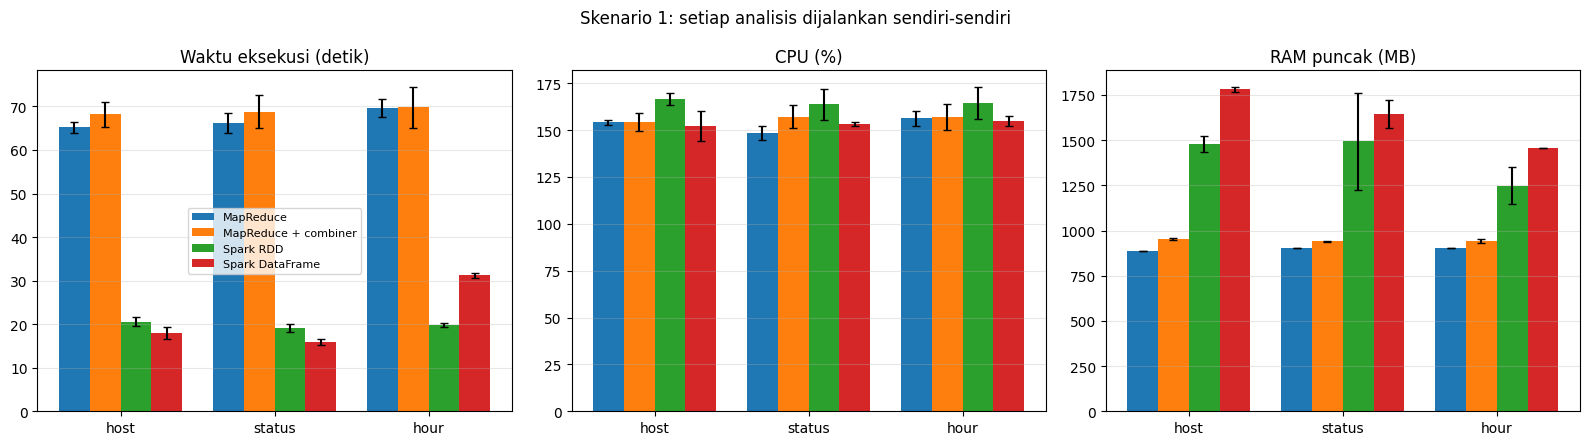

In [21]:
import matplotlib.pyplot as plt

METRIC_LABELS = {
    "waktu_s": "Waktu eksekusi (detik)",
    "cpu_persen": "CPU (%)",
    "ram_puncak_mb": "RAM puncak (MB)",
}
scenario1 = bench[bench["skenario"] == "1. per analisis"]
approach_names = list(APPROACHES)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (metric, label) in zip(axes, METRIC_LABELS.items()):
    stats = scenario1.groupby(["analisis", "pendekatan"])[metric].agg(["mean", "std"])
    width = 0.8 / len(approach_names)
    for i, name in enumerate(approach_names):
        means = [stats.loc[(a, name), "mean"] for a in ANALYSES]
        stds = [stats.loc[(a, name), "std"] for a in ANALYSES]
        positions = [x + i * width for x in range(len(ANALYSES))]
        ax.bar(positions, means, width, yerr=stds, capsize=3, label=name)
    ax.set_xticks([x + width * (len(approach_names) - 1) / 2 for x in range(len(ANALYSES))])
    ax.set_xticklabels(ANALYSES)
    ax.set_title(label)
    ax.grid(axis="y", alpha=0.3)
axes[0].legend(fontsize=8)
fig.suptitle("Skenario 1: setiap analisis dijalankan sendiri-sendiri")
fig.tight_layout()
fig.savefig(f"{RESULT_DIR}/skenario1.png", dpi=150)
plt.show()

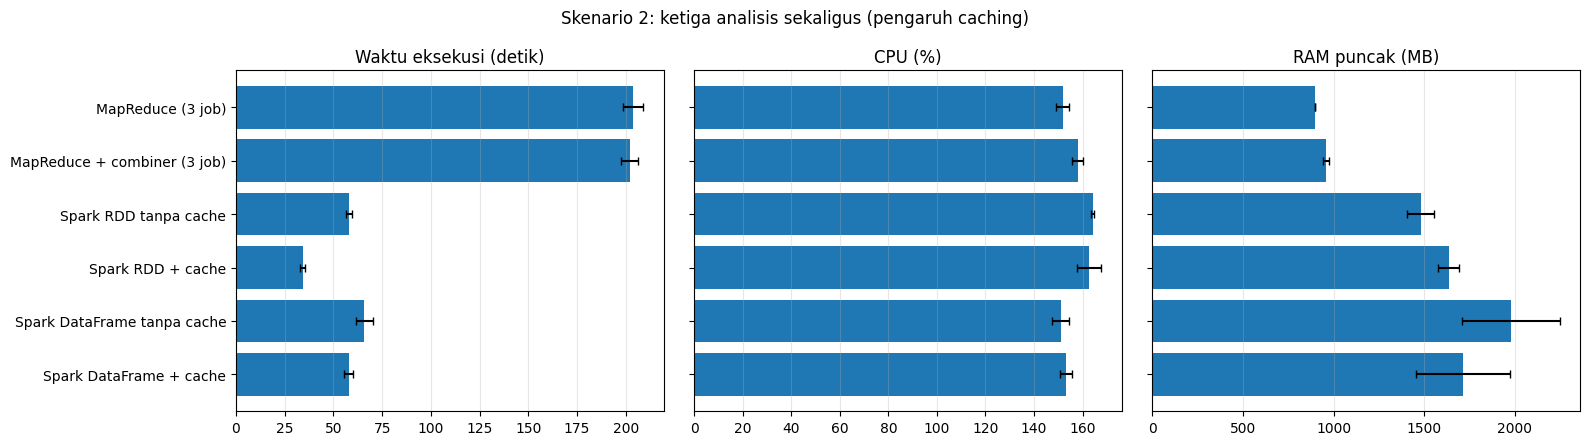

In [22]:
scenario2 = bench[bench["skenario"] == "2. tiga analisis sekaligus"]
stats2 = scenario2.groupby("pendekatan", sort=False)[list(METRIC_LABELS)].agg(["mean", "std"])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (metric, label) in zip(axes, METRIC_LABELS.items()):
    ax.barh(stats2.index, stats2[(metric, "mean")], xerr=stats2[(metric, "std")], capsize=3)
    ax.invert_yaxis()
    ax.set_title(label)
    ax.grid(axis="x", alpha=0.3)
for ax in axes[1:]:
    ax.set_yticklabels([])
fig.suptitle("Skenario 2: ketiga analisis sekaligus (pengaruh caching)")
fig.tight_layout()
fig.savefig(f"{RESULT_DIR}/skenario2.png", dpi=150)
plt.show()

In [23]:
# Perbandingan waktu terhadap MapReduce versi spesifikasi (tanpa combiner).
mean_time = scenario1.groupby(["analisis", "pendekatan"])["waktu_s"].mean().unstack().reindex(ANALYSES)
speedup = mean_time.rdiv(mean_time["MapReduce"], axis=0).round(2)
print("Berapa kali lebih cepat dibanding 'MapReduce' (nilai > 1 = lebih cepat):")
display(speedup[approach_names])

mean_time2 = scenario2.groupby("pendekatan", sort=False)["waktu_s"].mean()
print("\nSkenario 2, berapa kali lebih cepat dibanding 'MapReduce (3 job)':")
display((mean_time2["MapReduce (3 job)"] / mean_time2).round(2).to_frame("kali_lebih_cepat"))

Berapa kali lebih cepat dibanding 'MapReduce' (nilai > 1 = lebih cepat):


pendekatan,MapReduce,MapReduce + combiner,Spark RDD,Spark DataFrame
analisis,,,,
host,1.0,0.96,3.16,3.64
status,1.0,0.96,3.46,4.14
hour,1.0,1.00,3.52,2.23



Skenario 2, berapa kali lebih cepat dibanding 'MapReduce (3 job)':


,kali_lebih_cepat
pendekatan,
MapReduce (3 job),1.00
MapReduce + combiner (3 job),1.01
Spark RDD tanpa cache,3.50
Spark RDD + cache,5.93
Spark DataFrame tanpa cache,3.09
Spark DataFrame + cache,3.53


## 11. Hasil Analisis Data

Hasil diambil dari output Spark DataFrame (sudah terbukti identik dengan pendekatan lain di bagian 7).

In [24]:
host_counts = pd.Series(outputs[("Spark DataFrame", "host")]).sort_values(ascending=False)
status_counts = pd.Series(outputs[("Spark DataFrame", "status")]).sort_index()
hour_bytes = pd.Series(outputs[("Spark DataFrame", "hour")]).sort_index()

host_counts.head(10).to_frame("total_request").to_csv(f"{RESULT_DIR}/top10_host.csv")
status_counts.to_frame("total_request").to_csv(f"{RESULT_DIR}/status_code.csv")
(hour_bytes / 1024**2).round(1).to_frame("total_MB").to_csv(f"{RESULT_DIR}/traffic_per_jam.csv")

print(f"Jumlah host unik: {len(host_counts):,}")
display(host_counts.head(10).to_frame("total_request"))
display(status_counts.to_frame("total_request").assign(
    persen=lambda d: (100 * d["total_request"] / d["total_request"].sum()).round(3)))

Jumlah host unik: 137,978


,total_request
piweba3y.prodigy.com,21988
piweba4y.prodigy.com,16437
piweba1y.prodigy.com,12825
edams.ksc.nasa.gov,11964
163.206.89.4,9697
news.ti.com,8161
www-d1.proxy.aol.com,8047
alyssa.prodigy.com,8037
siltb10.orl.mmc.com,7573
www-a2.proxy.aol.com,7516


,total_request,persen
200,3100522,89.569
302,73070,2.111
304,266773,7.707
400,15,0.000
403,225,0.006
404,20901,0.604
500,65,0.002
501,41,0.001


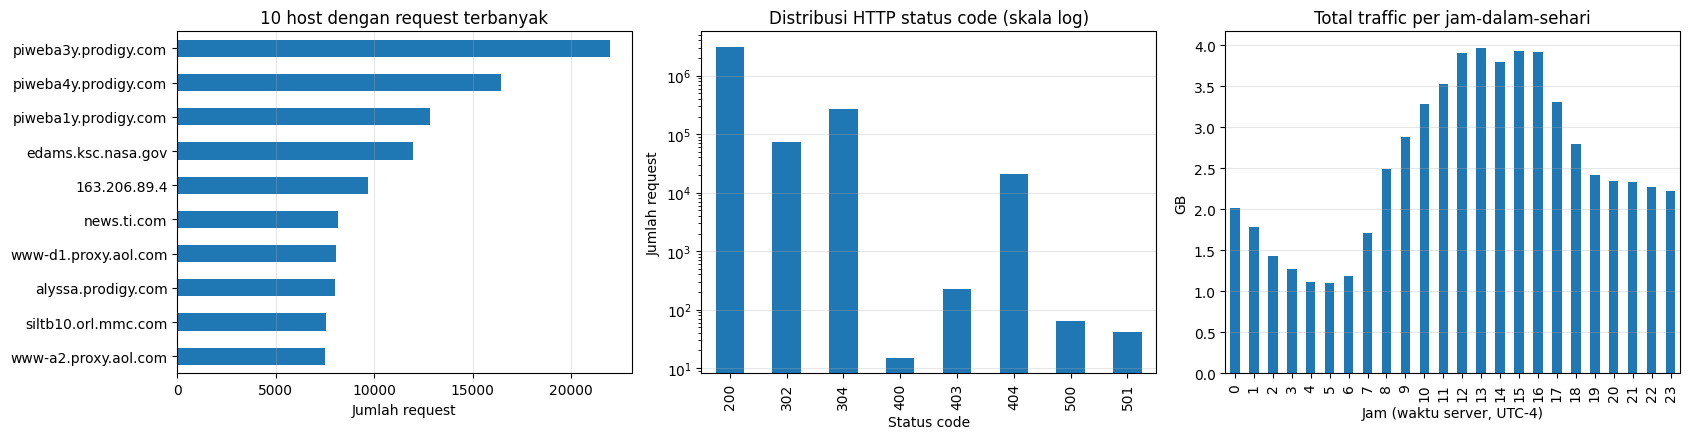

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

host_counts.head(10).sort_values().plot.barh(ax=axes[0])
axes[0].set_title("10 host dengan request terbanyak")
axes[0].set_xlabel("Jumlah request")

status_counts.plot.bar(ax=axes[1], logy=True)
axes[1].set_title("Distribusi HTTP status code (skala log)")
axes[1].set_xlabel("Status code")
axes[1].set_ylabel("Jumlah request")

(hour_bytes / 1024**3).plot.bar(ax=axes[2])
axes[2].set_title("Total traffic per jam-dalam-sehari")
axes[2].set_xlabel("Jam (waktu server, UTC-4)")
axes[2].set_ylabel("GB")

for ax in axes:
    ax.grid(axis="x" if ax is axes[0] else "y", alpha=0.3)
fig.tight_layout()
fig.savefig(f"{RESULT_DIR}/hasil_analisis.png", dpi=150)
plt.show()

## 12. Catatan untuk Laporan

**Keterbatasan eksperimen** (perlu disebut di Bab 1 dan Bab 3):

- Semua pendekatan berjalan di **satu mesin** (Google Colab), bukan cluster. Paralelisme berasal
  dari beberapa inti CPU; tidak ada HDFS, YARN, maupun biaya jaringan saat shuffle.
- "MapReduce" di sini adalah **mrjob runner `local` (Python murni)** yang meniru alur Hadoop,
  bukan Hadoop MapReduce (Java) di cluster.
- Ukuran data (±356 MB) masih muat di RAM satu mesin, sehingga keunggulan pemrosesan
  terdistribusi belum terlihat sepenuhnya dan biaya awal (misal menyalakan JVM) bisa dominan.
- Spesifikasi mesin Colab bisa berbeda antar-sesi; spesifikasi saat pengukuran tercatat di bagian 1.

**Pertanyaan pemandu untuk Bab 3** (jawab berdasarkan angka di bagian 10):

1. Seberapa besar selisih waktu MapReduce vs Spark? Apakah sesuai dugaan "Spark lebih cepat"?
2. Seberapa besar pengaruh combiner pada MapReduce, dan pada analisis mana paling terasa
   (petunjuk: analisis `status` hanya punya sedikit key)?
3. Mengapa Spark RDD (fungsi Python) dan Spark DataFrame (fungsi bawaan JVM) berbeda kecepatannya?
4. Pada skenario 2, berapa penghematan waktu yang diberikan `cache()`, dan berapa biaya RAM-nya?
5. Bagaimana pola CPU % dan RAM tiap pendekatan, dan apa penyebabnya (JVM, subproses, GC)?

In [26]:
spark.stop()